In [1]:
import numpy as numpy
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(f"Размер датасета: {df.shape[0]} клиентов и {df.shape[1]} признаков")
print(df.columns)

df=df.drop(["EmployeeCount", "EmployeeNumber"],axis=1)
df.info()
df.head(3)

Размер датасета: 1470 клиентов и 35 признаков
Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,2,80,0,7,3,3,0,0,0,0


In [3]:
economic_stats = df.groupby ("EducationField")[["DailyRate", "Education"]].mean()
print(economic_stats)

                   DailyRate  Education
EducationField                         
Human Resources   675.259259   3.111111
Life Sciences     804.425743   2.929043
Marketing         727.836478   3.125786
Medical           822.799569   2.803879
Other             796.024390   3.073171
Technical Degree  842.128788   2.825758


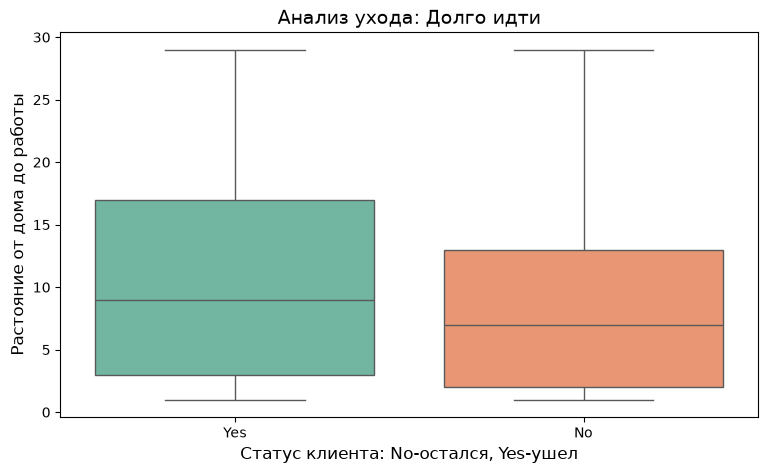

In [4]:
plt.figure(figsize=(9,5))
sns.boxplot (x="Attrition", y="DistanceFromHome", data=df, palette="Set2", legend=False, hue="Attrition")

plt.title("Анализ ухода: Долго идти", fontsize=14)
plt.xlabel("Статус клиента: No-остался, Yes-ушел", fontsize=12)
plt.ylabel("Растояние от дома до работы", fontsize=12)
plt.show()

In [5]:
x = pd.get_dummies(df.drop("Attrition", axis=1), columns=["Gender", "Department", "EducationField", "JobRole", "MaritalStatus", "Over18", "OverTime", "BusinessTravel"], drop_first=True)

y = df["Attrition"]
x.head(3)

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
0,41,1102,1,2,2,94,3,2,4,5993,...,False,False,False,True,False,False,True,True,False,True
1,49,279,8,1,3,61,2,2,2,5130,...,False,False,True,False,False,True,False,False,True,False
2,37,1373,2,2,4,92,2,1,3,2090,...,False,False,False,False,False,False,True,True,False,True


In [6]:
x_train, x_test,y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

number_cols = [ "Age",
                "DailyRate",
                "DistanceFromHome",
                "Education",
                "EnvironmentSatisfaction",
                "HourlyRate",
                "JobInvolvement",
                "JobLevel",
                "MonthlyIncome",
                "MonthlyRate",
                "NumCompaniesWorked",
                "PercentSalaryHike", 
                "PerformanceRating", 
                "RelationshipSatisfaction",
                "StandardHours", 
                "StockOptionLevel", 
                "TotalWorkingYears", 
                "TrainingTimesLastYear", 
                "WorkLifeBalance", 
                "YearsAtCompany", 
                "YearsInCurrentRole", 
                "YearsSinceLastPromotion",
                "YearsWithCurrManager"
                ]
scaler = StandardScaler()

x_train[number_cols] = scaler.fit_transform(x_train[number_cols])
x_test[number_cols] = scaler.transform(x_test[number_cols])
x_train.head(3)

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
1194,1.090194,1.049455,-0.899915,1.064209,-0.658710,-0.908436,1.795282,1.762189,2,2.026752,...,False,False,False,False,False,False,False,False,False,True
128,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,1.694111,0.373564,-0.986265,4,-0.864408,...,False,False,False,False,False,True,False,False,False,True
810,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,-0.662913,0.373564,1.762189,3,2.347706,...,False,False,False,False,False,True,False,False,False,True


In [7]:
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Точность модели (Accuracy):{accuracy:.2f}%\n")

Точность модели (Accuracy):84.01%

